# Age-Metallicity Relation (AMR) Analysis 

Here the Age-Metallicity Relation (AMR) for cleaned catalogues of globular clusters in Vandenberg (2013) & Krause (2016) will be outlined.

In [ ]:
# Import libraries.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("globular_clusters_cleaned.csv")
fehlabel = "[Fe/H] "
agelabel = "Age (Gyr)"
data.head()

,FeH,Age,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,...,r_h,mu_V,rho_0,lg_tc,lg_th,Mstar,rh,C5,Age_Krause,FeH_Krause
0,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,...,3.17,14.38,4.88,7.84,9.55,6.46,7.10,0.92,12.80,-0.76
1,-1.32,11.50,0.38,H,24,NaN,0.98,12.0,-6.75,10.9,...,2.23,20.05,1.78,8.99,9.32,0.46,9.80,0.05,12.20,-1.32
2,-1.30,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,...,0.82,14.80,4.74,7.76,8.93,2.50,3.50,0.72,10.00,-1.26
3,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,...,0.68,17.73,2.99,8.59,9.12,3.41,5.50,0.62,10.24,-1.08
4,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,...,0.51,14.25,5.09,7.43,8.82,5.51,3.05,1.81,7.64,-1.13


In [8]:
# Check data is loaded correctly
data.head()
data.columns

Index(['FeH', 'Age', 'Age_err', 'Method', 'Figs', 'Range', 'HBtype', 'R_G',
       'M_V', 'v_e0', 'log_sigma_0', 'Cluster_ID', 'RA', 'DEC', 'L', 'B',
       'R_Sun', 'R_gc', 'X', 'Y', 'Z', 'v_r', 'v_r_e', 'v_LSR', 'sig_v',
       'sig_v_e', 'c', 'r_c', 'r_h', 'mu_V', 'rho_0', 'lg_tc', 'lg_th',
       'Mstar', 'rh', 'C5', 'Age_Krause', 'FeH_Krause'],
      dtype='str')

In [9]:
# Check for missing values in the age and metallicity columns of both datasets
data[["Cluster_ID", "FeH", "Age", "Age_err", "FeH_Krause", "Age_Krause"]].isna().sum()

Cluster_ID    0
FeH           0
Age           0
Age_err       0
FeH_Krause    3
Age_Krause    3
dtype: int64

Original data labelling guide for VandenBerg et al. (2013).
- Cluster_ID: Identifier of the globular cluster
- FeH: Metallicity, [Fe/H], on the Carretta et al. (2009) scale (except Terzan 8, taken from Mottini, Wallerstein & McWilliam 2008)
- Age: Absolute age (Gyr)
- Age_err: Uncertainty in the age (Gyr). This is only the isochrone-fitting error (approximately ±0.25 Gyr); VandenBerg et al. note that distance and chemical abundance uncertainties add a further factor of approximately ±1.5-2 Gyr.
- HBtype: Horizontal branch morphology index, (B - R)/(B + V + R), from -1 (red HB) to +1 (blue HB)
- R_G: Galactocentric distance (kpc), from Harris (1996, 2010 edition)
- M_V: Absolute integrated visual magnitude, from Harris (1996, 2010 edition)

Original data labelling guide for Krause et al. (2016).
- Age_Krause: Age (Gyr), compiled from data sets.
- FeH_Krause: Metallicity, [Fe/H] 
- Mstar: Stellar mass ($10^5 M_\odot$)
- rh: Half-mass radius (pc)
- C5: Compactness, $M_*/r_h$ ($10^5 M_\odot$/pc)

In [10]:
# Confirm the total number of clusters in each dataset.
print(data["Cluster_ID"].nunique())                    # VandenBerg
print(data["Age_Krause"].notna().sum())                # Krause

# Clusters in VandenBerg that are missing from Krause
print(data.loc[data["Age_Krause"].isna(), "Cluster_ID"])

55
52
7     NGC4147
52       Arp2
54    Terzan8
Name: Cluster_ID, dtype: str


## Fitting the age-metallicity relation

A straight line, Age = a [Fe/H] + b, is fitted to each dataset. The fit is repeated, each time leaving out clusters more than 3σ from the line, so that extreme clusters do not pull the fit. The VandenBerg fit is weighted by 1/Age_err (note these errors are fitting errors only, so the weights reflect relative, not total, uncertainty). Krause gives no age errors, so its fit is unweighted.

Clusters whose residual from the final line is greater than 2σ are taken as outliers.

In [11]:
FeH, Age, Age_err = data["FeH"], data["Age"], data["Age_err"]
krause = data.dropna(subset=["Age_Krause", "FeH_Krause"]).copy()

def fit_amr(x, y, yerr=None, clip=3, niter=10):
    x, y = np.asarray(x), np.asarray(y)
    w = np.ones_like(x) if yerr is None else 1 / np.asarray(yerr)
    keep = np.ones_like(x, dtype=bool)
    for _ in range(niter):
        a, b = np.polyfit(x[keep], y[keep], 1, w=w[keep])
        resid = y - (a * x + b)
        sigma = np.std(resid[keep], ddof=2)
        new_keep = np.abs(resid) < clip * sigma
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return a, b, sigma, resid

aV, bV, sigmaV, residV = fit_amr(FeH, Age, Age_err)
data["residV"] = residV
print(f"VandenBerg: Age = {aV:.2f} [Fe/H] + {bV:.2f}, scatter = {sigmaV:.2f} Gyr")

aK, bK, sigmaK, residK = fit_amr(krause["FeH_Krause"], krause["Age_Krause"])
krause["residK"] = residK
print(f"Krause: Age = {aK:.2f} [Fe/H] + {bK:.2f}, scatter = {sigmaK:.2f} Gyr")

VandenBerg: Age = -0.92 [Fe/H] + 10.54, scatter = 0.48 Gyr
Krause: Age = -0.54 [Fe/H] + 11.75, scatter = 1.02 Gyr


In [12]:
out1 = data[np.abs(data["residV"]) > 2 * sigmaV]
out2 = krause[np.abs(krause["residK"]) > 2 * sigmaK]
print(out1[["Cluster_ID", "FeH", "Age", "residV"]])
print(out2[["Cluster_ID", "FeH_Krause", "Age_Krause", "residK"]])

   Cluster_ID   FeH    Age    residV
2      NGC362 -1.30  10.75 -0.993203
3     NGC1261 -1.27  10.75 -0.965497
23    NGC6218 -1.33  13.00  1.229091
28    NGC6362 -1.07  12.50  0.969208
53      Pal12 -0.81   9.00 -2.290674
   Cluster_ID  FeH_Krause  Age_Krause    residK
2      NGC362       -1.26       10.00 -2.430529
3     NGC1261       -1.08       10.24 -2.092629
4     NGC1851       -1.13        7.64 -4.719824
32    NGC6535       -1.51       10.50 -2.066502
53      Pal12       -0.81        8.60 -3.585779


## Plot 1: VandenBerg et al. (2013)

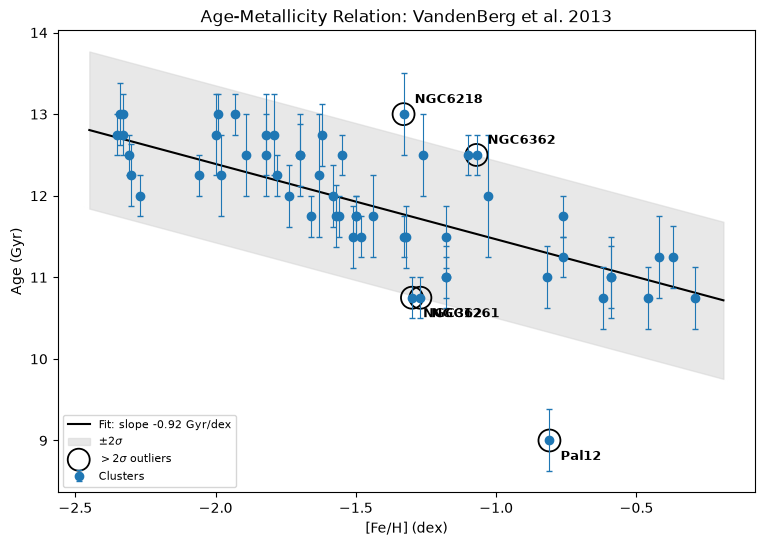

In [13]:
plt.figure(figsize=(9, 6))
xfit = np.linspace(FeH.min() - 0.1, FeH.max() + 0.1, 100)
plt.plot(xfit, aV * xfit + bV, "k-", label=f"Fit: slope {aV:.2f} Gyr/dex")
plt.fill_between(xfit, aV * xfit + bV - 2 * sigmaV, aV * xfit + bV + 2 * sigmaV,
                 color="lightgrey", alpha=0.5, label=r"$\pm 2\sigma$")
plt.errorbar(FeH, Age, yerr=Age_err, fmt="o", color="tab:blue", ms=6,
             elinewidth=0.8, capsize=2, label="Clusters")
plt.scatter(out1["FeH"], out1["Age"], s=250, facecolors="none",
            edgecolors="k", linewidths=1.3, label=r"$>2\sigma$ outliers")
for _, r in out1.iterrows():
    plt.annotate(r["Cluster_ID"], (r["FeH"], r["Age"]),
                 xytext=(8, -14 if r["residV"] < 0 else 8),
                 textcoords="offset points", fontsize=9, weight="bold")
plt.xlabel(fehlabel); plt.ylabel(agelabel)
plt.title("Age-Metallicity Relation: VandenBerg et al. 2013")
plt.legend(fontsize=8, loc="lower left")
plt.show()

In [67]:
print("VandenBerg outliers:", ", ".join(out1["Cluster_ID"]))

VandenBerg outliers: NGC362, NGC1261, NGC6218, NGC6362, Pal12


## Plot 2: Krause et al. (2016)

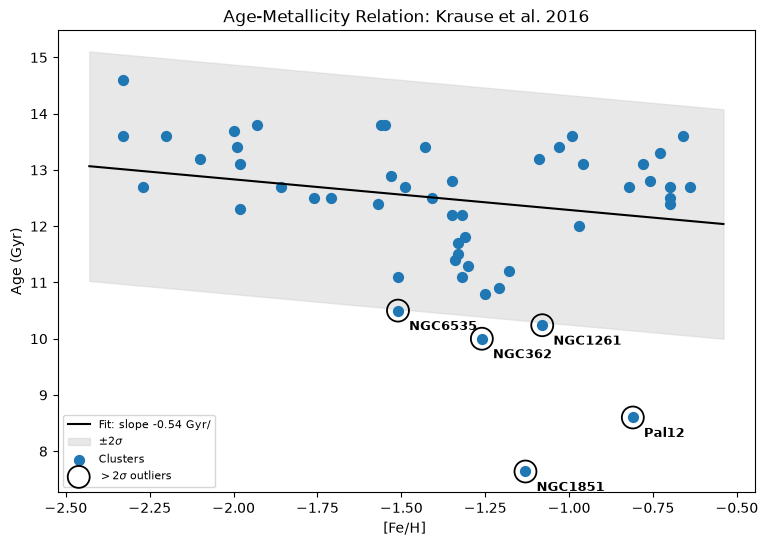

In [68]:
plt.figure(figsize=(9, 6))
xfit = np.linspace(krause["FeH_Krause"].min() - 0.1, krause["FeH_Krause"].max() + 0.1, 100)
plt.plot(xfit, aK * xfit + bK, "k-", label=f"Fit: slope {aK:.2f} Gyr/")
plt.fill_between(xfit, aK * xfit + bK - 2 * sigmaK, aK * xfit + bK + 2 * sigmaK,
                 color="lightgrey", alpha=0.5, label=r"$\pm 2\sigma$")
plt.scatter(krause["FeH_Krause"], krause["Age_Krause"], color="tab:blue", s=50, label="Clusters")
plt.scatter(out2["FeH_Krause"], out2["Age_Krause"], s=250, facecolors="none",
            edgecolors="k", linewidths=1.3, label=r"$>2\sigma$ outliers")
for _, r in out2.iterrows():
    plt.annotate(r["Cluster_ID"], (r["FeH_Krause"], r["Age_Krause"]),
                 xytext=(8, -14 if r["residK"] < 0 else 8),
                 textcoords="offset points", fontsize=9, weight="bold")
plt.xlabel(fehlabel); plt.ylabel(agelabel)
plt.title("Age-Metallicity Relation: Krause et al. 2016")
plt.legend(fontsize=8, loc="lower left")
plt.show()

In [69]:
print("Krause outliers:", ", ".join(out2["Cluster_ID"]))

Krause outliers: NGC362, NGC1261, NGC1851, NGC6535, Pal12
